In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

df = pd.read_csv("/content/weather.csv")
print("Shape:", df.shape)
display(df.head())
display(df.dtypes)
display(df.describe(include="all").T)
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (366, 22)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No


,0
MinTemp,float64
MaxTemp,float64
Rainfall,float64
Evaporation,float64
Sunshine,float64
WindGustDir,object
WindGustSpeed,float64
WindDir9am,object
WindDir3pm,object
WindSpeed9am,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
MinTemp,366.0,NaN,NaN,NaN,7.265574,6.0258,-5.3,2.3,7.45,12.5,20.9
MaxTemp,366.0,NaN,NaN,NaN,20.550273,6.690516,7.6,15.025,19.65,25.5,35.8
Rainfall,366.0,NaN,NaN,NaN,1.428415,4.2258,0.0,0.0,0.0,0.2,39.8
Evaporation,366.0,NaN,NaN,NaN,4.521858,2.669383,0.2,2.2,4.2,6.4,13.8
Sunshine,363.0,NaN,NaN,NaN,7.909366,3.481517,0.0,5.95,8.6,10.5,13.6
WindGustDir,363,16,NW,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WindGustSpeed,364.0,NaN,NaN,NaN,39.840659,13.059807,13.0,31.0,39.0,46.0,98.0
WindDir9am,335,16,SE,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WindDir3pm,365,16,NW,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WindSpeed9am,359.0,NaN,NaN,NaN,9.651811,7.951929,0.0,6.0,7.0,13.0,41.0


Missing values:
 MinTemp           0
MaxTemp           0
Rainfall          0
Evaporation       0
Sunshine          3
WindGustDir       3
WindGustSpeed     2
WindDir9am       31
WindDir3pm        1
WindSpeed9am      7
WindSpeed3pm      0
Humidity9am       0
Humidity3pm       0
Pressure9am       0
Pressure3pm       0
Cloud9am          0
Cloud3pm          0
Temp9am           0
Temp3pm           0
RainToday         0
RISK_MM           0
RainTomorrow      0
dtype: int64
Duplicate rows: 0


Step 2 – Data cleaning
Only the selected numerical columns are used. Missing target values are removed; missing input values are replaced with the median of that input column. Median imputation retains observations and is less sensitive to extreme values than mean imputation. No duplicate rows were found in the uploaded file. The categorical columns are not required for this selected numerical-feature model.

In [27]:
features = ["MinTemp", "Sunshine", "Humidity3pm", "Pressure3pm", "Cloud3pm", "WindSpeed3pm"]
target = "MaxTemp"

data = df[features + [target]].copy()
for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

before = len(data)
data = data.dropna(subset=[target]).copy()
missing_before = data[features].isna().sum()
medians = data[features].median()
data[features] = data[features].fillna(medians)

print("Rows removed due to missing target:", before - len(data))
print("Missing predictor values before imputation:\n", missing_before)
print("Median values used for imputation:\n", medians)
print("Final modelling shape:", data.shape)
print("Remaining missing values:", int(data.isna().sum().sum()))

Rows removed due to missing target: 0
Missing predictor values before imputation:
 MinTemp         0
Sunshine        3
Humidity3pm     0
Pressure3pm     0
Cloud3pm        0
WindSpeed3pm    0
dtype: int64
Median values used for imputation:
 MinTemp            7.45
Sunshine           8.60
Humidity3pm       43.00
Pressure3pm     1017.40
Cloud3pm           4.00
WindSpeed3pm      17.00
dtype: float64
Final modelling shape: (366, 7)
Remaining missing values: 0


Step 3 – Visualisation and correlations
Scatter plots show the relationship between each predictor and MaxTemp. The heatmap shows both target relationships and correlations among predictors. Correlation is association, not proof of causation.

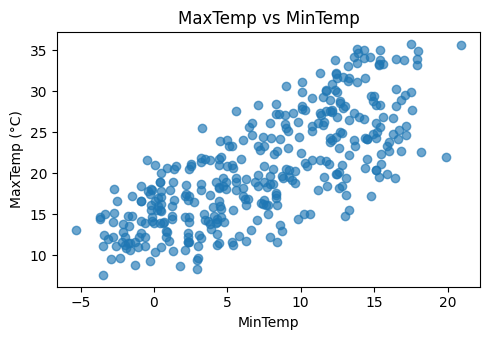

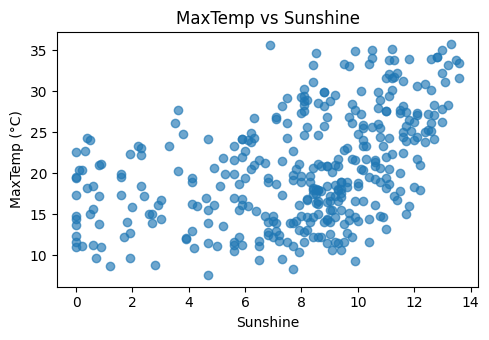

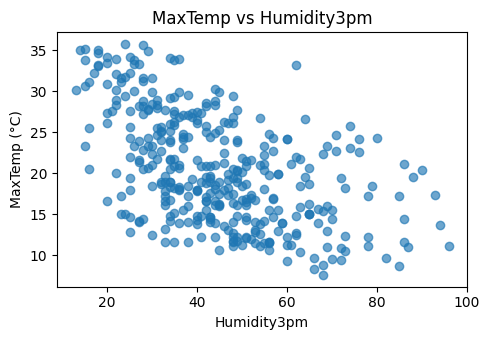

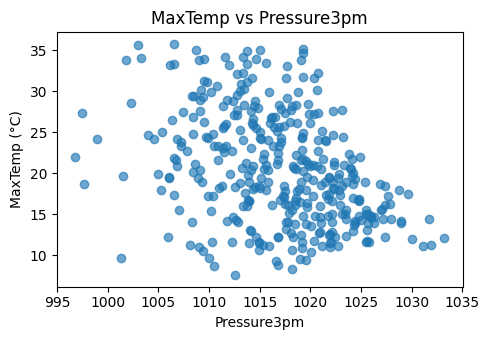

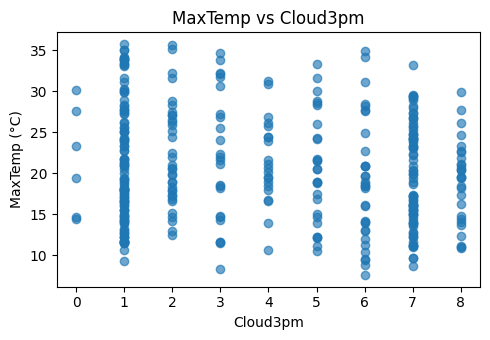

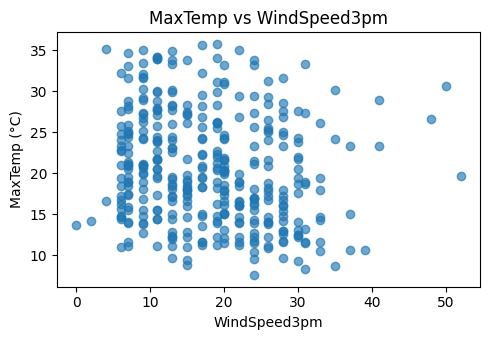

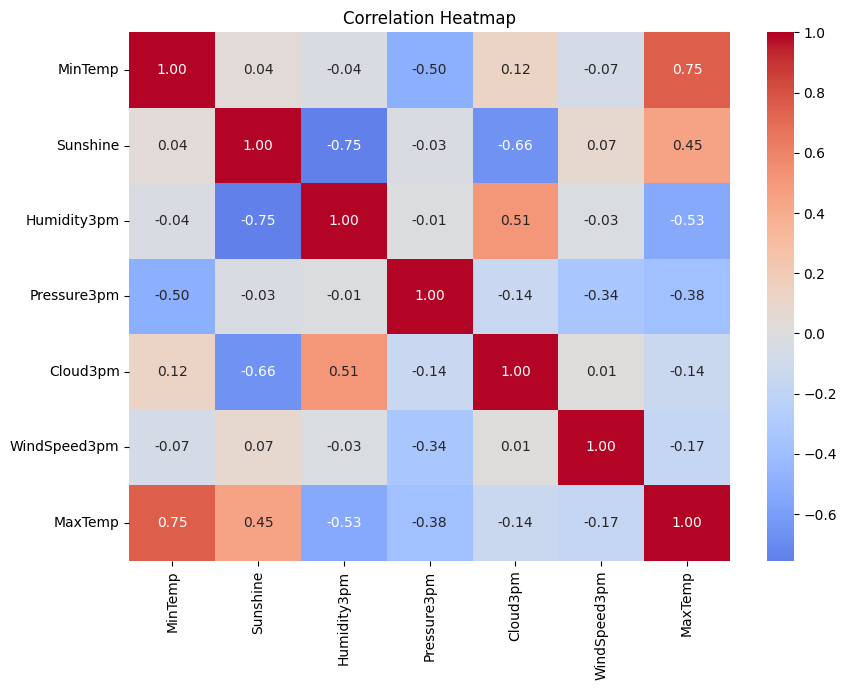

,MaxTemp
MaxTemp,1.000000
MinTemp,0.752471
Sunshine,0.450576
Cloud3pm,-0.135991
WindSpeed3pm,-0.167873
Pressure3pm,-0.379394
Humidity3pm,-0.533327


In [28]:
for col in features:
    plt.figure(figsize=(5, 3.5))
    plt.scatter(data[col], data[target], alpha=0.65)
    plt.xlabel(col)
    plt.ylabel("MaxTemp (°C)")
    plt.title(f"MaxTemp vs {col}")
    plt.tight_layout()
    plt.show()

corr = data.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(corr[target].sort_values(ascending=False))

Step 4 – Manual calculation using 6 observations
Use MinTemp as X1 and Sunshine as X2 for the first six records. The design matrix includes a column of ones for the intercept. The normal equation is:
\[
(X^T X)b = X^T y, \qquad b=(X^TX)^{-1}X^Ty
\]
The following code prints every matrix needed to show the manual least-squares calculation. numpy.linalg.solve solves the normal equations without explicitly calculating the inverse.

In [29]:
small = data.iloc[:6][["MinTemp", "Sunshine", "MaxTemp"]].copy()
display(small)

X_small = np.column_stack([np.ones(len(small)), small["MinTemp"], small["Sunshine"]])
y_small = small["MaxTemp"].to_numpy()

print("Design matrix X =\n", X_small)
print("Target vector y =\n", y_small)
XtX = X_small.T @ X_small
Xty = X_small.T @ y_small
print("X transpose X =\n", XtX)
print("X transpose y =\n", Xty)

b = np.linalg.solve(XtX, Xty)
print("Coefficients [b0, b1, b2] =", b)
print(f"Fitted equation: MaxTemp = {b[0]:.4f} + ({b[1]:.4f})*MinTemp + ({b[2]:.4f})*Sunshine")

# Predict the first observation and calculate its residual
manual_prediction = X_small[0] @ b
manual_residual = y_small[0] - manual_prediction
print("First observation actual:", y_small[0])
print("First observation predicted:", manual_prediction)
print("Residual (actual - predicted):", manual_residual)

# Verify the same six observations using scikit-learn
small_model = LinearRegression().fit(small[["MinTemp", "Sunshine"]], small["MaxTemp"])
print("Library intercept:", small_model.intercept_)
print("Library coefficients:", small_model.coef_)

,MinTemp,Sunshine,MaxTemp
0,8.0,6.3,24.3
1,14.0,9.7,26.9
2,13.7,3.3,23.4
3,13.3,9.1,15.5
4,7.6,10.6,16.1
5,6.2,8.2,16.9


Design matrix X =
 [[ 1.   8.   6.3]
 [ 1.  14.   9.7]
 [ 1.  13.7  3.3]
 [ 1.  13.3  9.1]
 [ 1.   7.6 10.6]
 [ 1.   6.2  8.2]]
Target vector y =
 [24.3 26.9 23.4 15.5 16.1 16.9]
X transpose X =
 [[  6.    62.8   47.2 ]
 [ 62.8  720.78 483.84]
 [ 47.2  483.84 407.08]]
X transpose y =
 [ 123.1  1324.87  941.53]
Coefficients [b0, b1, b2] = [20.38604065  0.47506183 -0.61546879]
Fitted equation: MaxTemp = 20.3860 + (0.4751)*MinTemp + (-0.6155)*Sunshine
First observation actual: 24.3
First observation predicted: 20.30908192062409
Residual (actual - predicted): 3.990918079375909
Library intercept: 20.386040646743588
Library coefficients: [ 0.47506183 -0.61546879]


Step 5 – Train/test split and model fitting
Use an 80:20 split with random_state=42 so results are reproducible. The strongest single predictor by absolute training-set correlation is used for the baseline. No scaling is required for ordinary least squares; raw coefficients remain in the original units.

In [30]:
X = data[features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

train_corr = X_train.join(y_train).corr(numeric_only=True)[target].drop(target)
best_feature = train_corr.abs().idxmax()
print("Baseline feature selected:", best_feature, "with training correlation", train_corr[best_feature])

baseline = LinearRegression().fit(X_train[[best_feature]], y_train)
multiple = LinearRegression().fit(X_train, y_train)

print("Baseline intercept:", baseline.intercept_)
print("Baseline coefficient:", baseline.coef_[0])
print("Multiple model intercept:", multiple.intercept_)
display(pd.DataFrame({"Feature": features, "Coefficient": multiple.coef_}))

Training observations: 292
Testing observations: 74
Baseline feature selected: MinTemp with training correlation 0.7499974496052473
Baseline intercept: 14.48767142470816
Baseline coefficient: 0.8415321712615711
Multiple model intercept: 139.22714853496336


,Feature,Coefficient
0,MinTemp,0.721943
1,Sunshine,0.343147
2,Humidity3pm,-0.177112
3,Pressure3pm,-0.115064
4,Cloud3pm,0.265718
5,WindSpeed3pm,-0.158164


Step 6 – Coefficient interpretation
The multiple model equation is formed from the fitted intercept and coefficients. Each coefficient describes the predicted change in MaxTemp (°C) for a one-unit increase in that feature, while holding the other selected features constant. This is a conditional model interpretation, not a causal claim. The intercept is the predicted temperature when all predictors equal zero; this combination is not necessarily realistic for this dataset.

Standardised coefficients are calculated below to compare relative coefficient magnitudes without the original measurement units.

In [31]:
print("MaxTemp = {:.4f}".format(multiple.intercept_) +
      "".join([f" + ({coef:.4f} × {name})" for name, coef in zip(features, multiple.coef_)]))

std_coefs = multiple.coef_ * X_train.std(ddof=0).to_numpy() / y_train.std(ddof=0)
display(pd.DataFrame({"Feature": features, "Raw coefficient": multiple.coef_,
                      "Standardised coefficient": std_coefs}).sort_values(
                          "Standardised coefficient", key=abs, ascending=False))

MaxTemp = 139.2271 + (0.7219 × MinTemp) + (0.3431 × Sunshine) + (-0.1771 × Humidity3pm) + (-0.1151 × Pressure3pm) + (0.2657 × Cloud3pm) + (-0.1582 × WindSpeed3pm)


,Feature,Raw coefficient,Standardised coefficient
0,MinTemp,0.721943,0.643416
2,Humidity3pm,-0.177112,-0.448739
5,WindSpeed3pm,-0.158164,-0.213372
1,Sunshine,0.343147,0.177315
3,Pressure3pm,-0.115064,-0.110974
4,Cloud3pm,0.265718,0.106154


Step 7 and 8 – Test predictions and evaluation
All reported metrics below are calculated on the held-out test set, not the training set. Adjusted R² is calculated using the number of test observations and the number of predictors; it penalises model complexity.

In [32]:
def evaluate(model, Xtr, Xte, ytrue, p):
    pred = model.predict(Xte)
    n = len(ytrue)
    r2 = r2_score(ytrue, pred)
    adj_r2 = 1 - (1-r2)*(n-1)/(n-p-1)
    return {
        "MAE": mean_absolute_error(ytrue, pred),
        "MSE": mean_squared_error(ytrue, pred),
        "RMSE": mean_squared_error(ytrue, pred)**0.5,
        "R2": r2,
        "Adjusted R2": adj_r2
    }, pred

base_metrics, base_pred = evaluate(baseline, X_train[[best_feature]], X_test[[best_feature]], y_test, 1)
multi_metrics, multi_pred = evaluate(multiple, X_train, X_test, y_test, len(features))
comparison = pd.DataFrame([base_metrics, multi_metrics],
                          index=[f"Single feature ({best_feature})", "Multiple features"])
display(comparison)

predictions = pd.DataFrame({"Actual MaxTemp": y_test, "Predicted MaxTemp": multi_pred})
display(predictions.head(10))

,MAE,MSE,RMSE,R2,Adjusted R2
Single feature (MinTemp),3.481406,18.015704,4.244491,0.574391,0.568480
Multiple features,2.258335,8.825781,2.970822,0.791497,0.772825


,Actual MaxTemp,Predicted MaxTemp
193,19.2,20.824480
33,26.5,26.423561
15,32.1,30.928200
310,16.1,20.061510
57,28.3,29.531341
183,17.3,16.217807
76,33.2,26.981924
119,17.3,19.972097
152,21.8,20.288749
126,31.8,30.255659


Step 9 – Residual analysis and assumptions
Residual = actual value − predicted value. A good residual plot should show random scatter around zero with no clear pattern and roughly constant spread. A roughly symmetric histogram is consistent with (but does not prove) normally distributed errors.

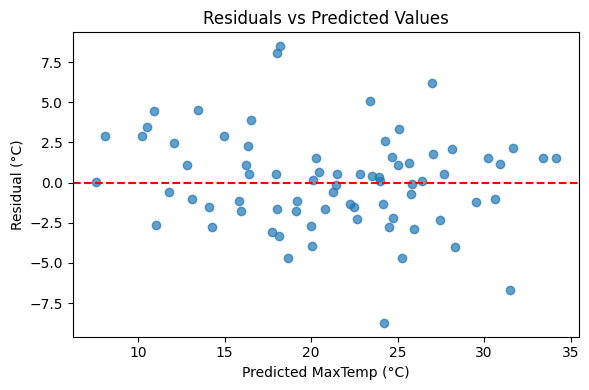

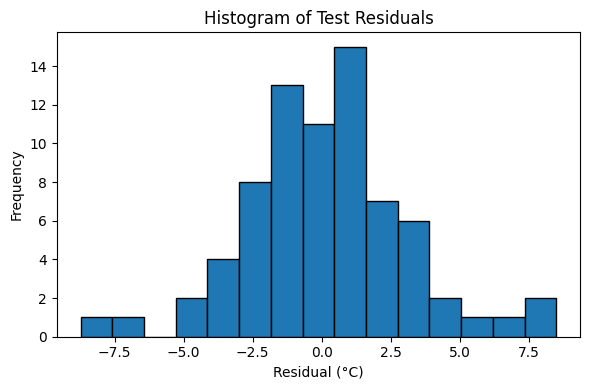

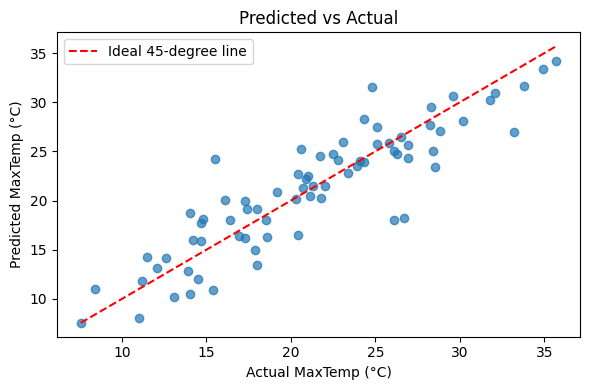

Residual mean: 0.10218952994366717
Residual standard deviation: 2.9893303691287394


In [33]:
residuals = y_test - multi_pred

plt.figure(figsize=(6, 4))
plt.scatter(multi_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted MaxTemp (°C)")
plt.ylabel("Residual (°C)")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=15, edgecolor="black")
plt.xlabel("Residual (°C)")
plt.ylabel("Frequency")
plt.title("Histogram of Test Residuals")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(y_test, multi_pred, alpha=0.7)
lims = [min(y_test.min(), multi_pred.min()), max(y_test.max(), multi_pred.max())]
plt.plot(lims, lims, "r--", label="Ideal 45-degree line")
plt.xlabel("Actual MaxTemp (°C)")
plt.ylabel("Predicted MaxTemp (°C)")
plt.title("Predicted vs Actual")
plt.legend()
plt.tight_layout()
plt.show()

print("Residual mean:", residuals.mean())
print("Residual standard deviation:", residuals.std())

In [34]:
# VIF is calculated on training predictors only
X_vif = sm.add_constant(X_train)
vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
display(vif_table)

print("Training predictor correlation matrix:")
display(X_train.corr())

,Feature,VIF
0,const,1.000000
1,MinTemp,1.452481
2,Sunshine,3.370866
3,Humidity3pm,2.552116
4,Pressure3pm,1.679680
5,Cloud3pm,1.898383
6,WindSpeed3pm,1.306061


Training predictor correlation matrix:


,MinTemp,Sunshine,Humidity3pm,Pressure3pm,Cloud3pm,WindSpeed3pm
MinTemp,1.000000,0.038268,-0.037383,-0.470075,0.122783,-0.083521
Sunshine,0.038268,1.000000,-0.778928,-0.041180,-0.661685,0.077202
Humidity3pm,-0.037383,-0.778928,1.000000,0.006584,0.525997,-0.055317
Pressure3pm,-0.470075,-0.041180,0.006584,1.000000,-0.140865,-0.375914
Cloud3pm,0.122783,-0.661685,0.525997,-0.140865,1.000000,0.012723
WindSpeed3pm,-0.083521,0.077202,-0.055317,-0.375914,0.012723,1.000000


Step 10 – New example and conclusion
The new example below uses plausible values inside the training-data ranges. It is an illustrative prediction, not a weather forecast. Avoid extrapolating beyond the observed feature ranges

In [35]:
new_record = pd.DataFrame([{
    "MinTemp": 10.0,
    "Sunshine": 8.0,
    "Humidity3pm": 50.0,
    "Pressure3pm": 1015.0,
    "Cloud3pm": 4.0,
    "WindSpeed3pm": 15.0
}], columns=features)

for col in features:
    assert X_train[col].min() <= new_record.loc[0, col] <= X_train[col].max(), f"{col} is outside training range"

new_prediction = multiple.predict(new_record)[0]
display(new_record)
print(f"Predicted maximum temperature: {new_prediction:.2f} °C")

print("Conclusion:")
print("Compare the test-set MAE, RMSE, R2 and adjusted R2 for both models.")
print("Extra features are useful here only if the test metrics improve enough to justify the added complexity.")
print("This linear model may miss nonlinear effects, time dependence and other unobserved weather factors.")

,MinTemp,Sunshine,Humidity3pm,Pressure3pm,Cloud3pm,WindSpeed3pm
0,10.0,8.0,50.0,1015.0,4.0,15.0


Predicted maximum temperature: 22.24 °C
Conclusion:
Compare the test-set MAE, RMSE, R2 and adjusted R2 for both models.
Extra features are useful here only if the test metrics improve enough to justify the added complexity.
This linear model may miss nonlinear effects, time dependence and other unobserved weather factors.
